# EchoPath — Run & Check (no Jetson required)

Runs the **exact deployment logic** on this machine so you can see and hear the system
work before any hardware arrives.

All logic is imported from `echopath_run.py`, which is generated from
`EchoPath_Jetson_Pipeline.ipynb` by the same extractor that produces
`echopath_device.py`. So the fusion, tracking and alert-policy code executing in this
notebook is **byte-identical** to what will run on the Jetson — only the backend differs
(PyTorch here, TensorRT there).

| | This notebook | Jetson |
|---|---|---|
| Detector | Ultralytics `best.pt` | TensorRT `.plan` (FP16) |
| Depth | MiDaS Small via torch | TensorRT `.plan` (FP16) |
| Fusion / alerts / audio | **same code** | **same code** |

Run the cells top to bottom.

## 1 · Load the pipeline

In [49]:
import os, json, time, importlib
import numpy as np, cv2
import matplotlib.pyplot as plt
%matplotlib inline

import echopath_run as ep
from echopath_run import (build_backends, discover_videos, iter_video_file,
                          AlertPolicy, ZoneClassifier, Tracker, AudioOut,
                          fuse, attach_geometric, generate_alerts, annotate,
                          direction_of, zone_from_metres, phrase_for,
                          geometric_distance, run_one)

print('imgsz            :', ep.IMGSZ)
print('depth mode       :', ep.DEPTH_MODE)
print('cooldown / gap   : %.1fs / %.1fs' % (ep.ALERT_COOLDOWN_S, ep.MIN_GAP_S))
print('silent classes   :', ', '.join(ep.SILENT_CLASSES))
print('videos found     :', len(discover_videos()))

for label, path in [('onnx', ep.ONNX_DIR), ('vocabulary', ep.VOCAB_DIR),
                    ('logs', ep.OUTPUT_DIR)]:
    n = len(os.listdir(path)) if os.path.isdir(path) else 0
    print('%-16s : %d files  (%s)' % (label, n, path))

imgsz            : 416
depth mode       : midas
cooldown / gap   : 2.5s / 1.0s
silent classes   : whiteboard, monitor, notice_board, window, backpack, handbag
videos found     : 13
onnx             : 5 files  (E:\EchoPath\onnx)
vocabulary       : 85 files  (E:\EchoPath\assets\audio)
logs             : 21 files  (E:\EchoPath\out_jetson)


## 2 · Load the models

First run takes ~20 s (YOLO + MiDaS). Everything after this is fast.

In [50]:
# ==========================================================================
MODE = 'midas'      # <<<<<<  'midas'  or  'geometric'  -- change this line
# ==========================================================================
# midas     -> RELATIVE. Zones come from each frame's own depth percentiles.
#              Overlay reads  p=0.71  (normalised inverse depth, higher = closer).
# geometric -> ABSOLUTE metres from box geometry. Overlay reads  2.4m.
#              No depth network, so ~1.4x faster. Accuracy +/-25-35% until
#              F_PX and Y_HORIZON are measured (see the last cell).

ep.DEPTH_MODE = MODE
detector, depther = build_backends()

kind = 'relative (frame-percentile zones)' if MODE == 'midas' else 'absolute metres'
print('MODE     :', MODE, '->', kind)
print('detector : %d classes' % len(detector.names))
print('classes  :', ', '.join(detector.names))
print('depth    :', 'geometric (no network)' if depther is None else 'MiDaS Small 256x256')

if MODE == 'geometric':
    print('zones    : close < %.1f m,  medium < %.1f m' % (ep.CLOSE_M, ep.MEDIUM_M))
    print('f_px     : %.0f (estimated, +/-7%%)' % ep.effective_f_px(1080, 1920))
    print('horizon  : %s' % ('row %d (measured)' % ep.Y_HORIZON
                             if ep.Y_HORIZON is not None else 'assumed level (frame_h/2)'))


Loading weights:  None


Using cache found in C:\Users\AIDSHPCLAB30/.cache\torch\hub\rwightman_gen-efficientnet-pytorch_master


MODE     : midas -> relative (frame-percentile zones)
detector : 19 classes
classes  : person, chair, door, stairs, slide, whiteboard, notice_board, elevator, column, window, water_dispenser, backpack, handbag, potted_plant, waste_bin, fire_extinguisher, wet_floor_sign, table, monitor
depth    : MiDaS Small 256x256


## 3 · Run one video and read the alerts

This is what the user would actually hear, with timestamps.

In [51]:
VIDEO = 'Classroom.MP4'          # <-- try lab.mp4, first_floor.mp4, Stairs.MP4, sign.mp4

path = os.path.join(ep.VIDEO_DIR, VIDEO)
cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30.0; cap.release()

log, nframes, elapsed = run_one(path, detector, depther, None, False, fps)

print('\n%d frames | %d alerts | %.1f fps' % (nframes, len(log), nframes/max(elapsed,1e-6)))
print('\n%-9s %-18s %-9s %-8s' % ('time', 'object', 'zone', 'where'))
for a in log:
    print('%7.2fs  %-18s %-9s %-8s' % (a['t'], a['label'], a['proximity'], a['direction']))

gaps = [round(b['t']-a['t'],2) for a,b in zip(log, log[1:])]
if gaps:
    print('\ngap between alerts: min %.2fs  median %.2fs   (floor is %.1fs)'
          % (min(gaps), float(np.median(gaps)), ep.MIN_GAP_S))

  [  4.00s] chair close on your left
  [  5.50s] chair medium ahead
  [  6.53s] chair close on your left
  [  8.93s] chair medium on your right
  [ 11.30s] chair medium on your left
  [ 12.67s] chair medium ahead
  [ 14.10s] chair medium on your right
  [ 15.13s] chair medium on your left
  [ 16.87s] chair close on your right
  [ 18.30s] chair medium ahead

566 frames | 10 alerts | 31.1 fps

time      object             zone      where   
   4.00s  chair              close     left    
   5.50s  chair              medium    ahead   
   6.53s  chair              close     left    
   8.93s  chair              medium    right   
  11.30s  chair              medium    left    
  12.67s  chair              medium    ahead   
  14.10s  chair              medium    right   
  15.13s  chair              medium    left    
  16.86s  chair              close     right   
  18.30s  chair              medium    ahead   

gap between alerts: min 1.03s  median 1.43s   (floor is 1.0s)


## 4 · See it — annotated frames

Red = close, orange = medium, green = far. These are the frames the alerts came from.

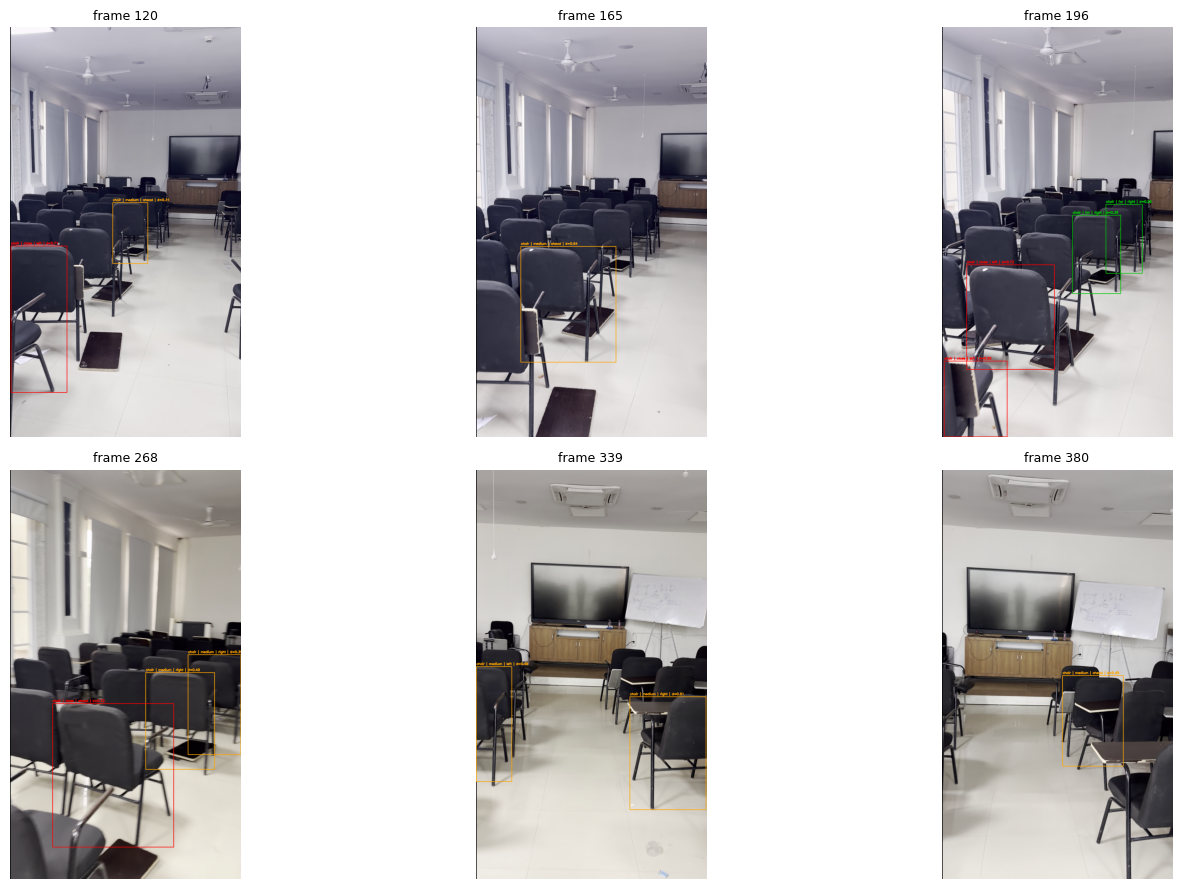

In [52]:
def sample_annotated(video, at_frames):
    zoner, tracker = ZoneClassifier(), Tracker()
    want, shots, dmap, idx = set(at_frames), {}, None, 0
    for frame in iter_video_file(os.path.join(ep.VIDEO_DIR, video)):
        h, w = frame.shape[:2]
        dets = detector.infer(frame)
        if depther is not None and idx % ep.DEPTH_EVERY_N == 0:
            dmap = depther.infer(frame)
        dets = tracker.update(attach_geometric(fuse(dets, dmap, w, h, zoner), h, w))
        if idx in want:
            shots[idx] = (annotate(frame, dets), dmap.copy() if dmap is not None else None)
            if len(shots) == len(want):
                break
        idx += 1
    return shots

picks = [a['frame'] for a in log[:6]] or [60, 120, 180, 240, 300, 360]
shots = sample_annotated(VIDEO, picks)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, f in zip(axes.ravel(), picks):
    if f in shots:
        ax.imshow(cv2.cvtColor(shots[f][0], cv2.COLOR_BGR2RGB))
        ax.set_title('frame %d' % f, fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 5 · What the depth stage actually sees

Left: the frame. Right: MiDaS depth (brighter = nearer) with the two percentile
thresholds that decide `close` / `medium` / `far`.

Watch how close the object's median depth sits to the P75 line — this is the behaviour
that makes obstacles under-report as `medium` during an approach.

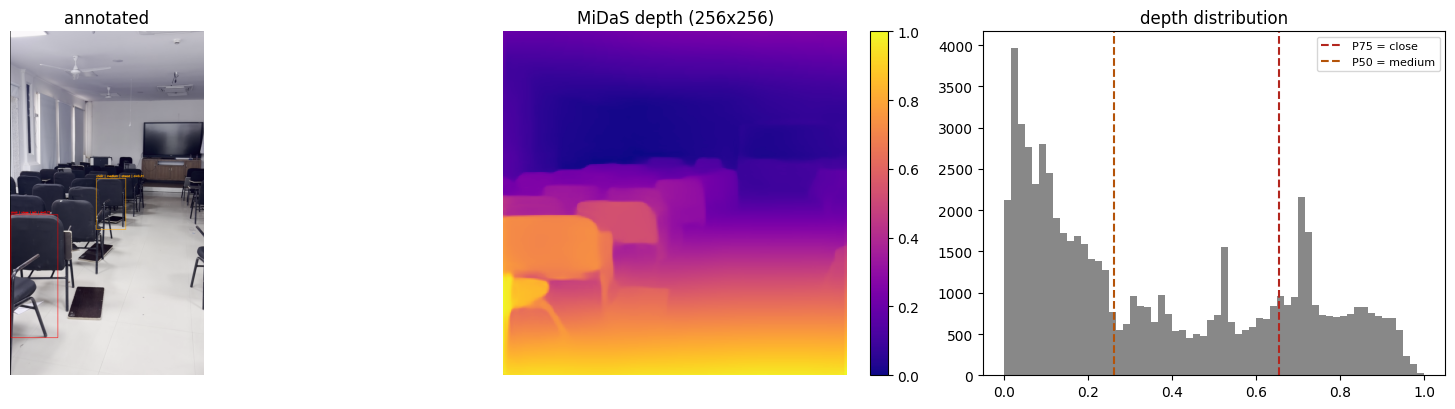

close threshold 0.653   medium threshold 0.263


In [53]:
f0 = picks[0]
if f0 in shots and shots[f0][1] is not None:
    dmap = shots[f0][1]
    p75, p50 = np.percentile(dmap, [ep.CLOSE_PCTL, ep.MEDIUM_PCTL])
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax[0].imshow(cv2.cvtColor(shots[f0][0], cv2.COLOR_BGR2RGB)); ax[0].set_title('annotated')
    im = ax[1].imshow(dmap, cmap='plasma'); ax[1].set_title('MiDaS depth (256x256)')
    plt.colorbar(im, ax=ax[1], fraction=0.046)
    ax[2].hist(dmap.ravel(), bins=60, color='#888')
    ax[2].axvline(p75, color='#b3261e', ls='--', label='P75 = close')
    ax[2].axvline(p50, color='#b45309', ls='--', label='P50 = medium')
    ax[2].set_title('depth distribution'); ax[2].legend(fontsize=8)
    for a in ax[:2]: a.axis('off')
    plt.tight_layout(); plt.show()
    print('close threshold %.3f   medium threshold %.3f' % (p75, p50))
else:
    print('run cell 4 first (or DEPTH_MODE is geometric)')

## 6 · MiDaS vs geometric on the same video

`geometric` drops the depth network entirely and computes distance from box geometry.
It is faster; whether it is *better* cannot be settled until the IMX219 is calibrated.

In [54]:
res = {}
for mode in ('midas', 'geometric'):
    ep.DEPTH_MODE = mode
    det2, dep2 = build_backends()
    lg, nf, el = run_one(path, det2, dep2, None, False, fps)
    res[mode] = dict(alerts=len(lg), fps=nf/max(el,1e-6), log=lg)
    print('%-10s %3d alerts   %.1f fps' % (mode, len(lg), res[mode]['fps']))
ep.DEPTH_MODE = 'midas'

print('\n%-9s %-22s | %-9s %s' % ('time', 'midas', 'time', 'geometric'))
for i in range(max(len(res['midas']['log']), len(res['geometric']['log']))):
    a = res['midas']['log'][i]     if i < len(res['midas']['log'])     else None
    b = res['geometric']['log'][i] if i < len(res['geometric']['log']) else None
    fmt = lambda x: ('%6.2fs  %-22s' % (x['t'], x['phrase'])) if x else ' ' * 30
    print('%s| %s' % (fmt(a), fmt(b)))

Loading weights:  None


Using cache found in C:\Users\AIDSHPCLAB30/.cache\torch\hub\rwightman_gen-efficientnet-pytorch_master


  [  4.00s] chair close on your left
  [  5.50s] chair medium ahead
  [  6.53s] chair close on your left
  [  8.93s] chair medium on your right
  [ 11.30s] chair medium on your left
  [ 12.67s] chair medium ahead
  [ 14.10s] chair medium on your right
  [ 15.13s] chair medium on your left
  [ 16.87s] chair close on your right
  [ 18.30s] chair medium ahead
midas       10 alerts   31.6 fps
  [  4.00s] chair close on your left
  [  5.50s] chair close ahead
  [  6.53s] chair close on your left
  [  8.93s] chair close on your right
  [ 11.30s] chair close on your left
  [ 12.67s] chair close ahead
  [ 13.77s] chair close ahead
  [ 14.80s] chair close on your left
  [ 15.93s] chair medium on your right
  [ 17.43s] chair close on your left
  [ 18.47s] chair close ahead
geometric   11 alerts   44.4 fps

time      midas                  | time      geometric
  4.00s  chair close on your left|   4.00s  chair close on your left
  5.50s  chair medium ahead    |   5.50s  chair close ahead     
  6

## 7 · Hear it

Plays the pre-rendered WAVs — the same 85 files the Jetson will use. Zero synthesis at
runtime, which is how the alert latency stays low on a 4 GB Maxwell board.

In [55]:
from IPython.display import Audio, display
for key in ['chair_close_ahead', 'stairs_close_on_your_left', 'system_ready']:
    p = os.path.join(ep.VOCAB_DIR, key + '.wav')
    if os.path.exists(p):
        print(key); display(Audio(p))
    else:
        print('missing:', p)

chair_close_ahead


missing: E:\EchoPath\assets\audio\stairs_close_on_your_left.wav
system_ready


## 8 · Process **every** video → annotated + voiced output

The `VIDEO_JOBS` loop, same shape as `with_TTS (2)` cells 7 and 11, but using the new
alert policy and the pre-rendered vocabulary.

For each of the 13 videos it writes:

| file | contents |
|---|---|
| `echopath_<name>.mp4` | annotated video — boxes coloured by zone, labels, live alert overlay |
| `echopath_<name>_voiced.mp4` | the same video with the spoken alerts muxed in at their timestamps |
| `workstation__<name>.jsonl` | machine-readable alert log (the Jetson fidelity baseline) |

Audio is **not synthesised** here — it reuses the 85 pre-rendered WAVs, which is exactly
what the Jetson does. Takes roughly 10-15 minutes for all 13.

In [56]:
import subprocess, tempfile, shutil
import imageio_ffmpeg
FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()

# ---------------------------------------------------------------- settings
PROCESS_ALL  = True          # False -> skip this cell
SAVE_VIDEO   = True          # write the annotated .mp4
BAKE_AUDIO   = True          # also write the _voiced.mp4
LIMIT        = None          # e.g. 2 to try on the first two videos only

VIDEO_OUT_DIR = os.path.join(ep.OUTPUT_DIR, 'videos')
if not os.path.isdir(VIDEO_OUT_DIR):
    os.makedirs(VIDEO_OUT_DIR)

# ---------------------------------------------------------------- job list
VIDEO_JOBS = [(p, os.path.join(VIDEO_OUT_DIR, 'echopath_' + os.path.basename(p)))
              for p in discover_videos()]
if LIMIT:
    VIDEO_JOBS = VIDEO_JOBS[:LIMIT]
print('%d job(s):' % len(VIDEO_JOBS))
for i, o in VIDEO_JOBS:
    print('  %-20s -> %s' % (os.path.basename(i), os.path.basename(o)))


def process_job(in_path, out_path):
    """Full pipeline over one video: annotate every frame, log alerts, write mp4."""
    policy, zoner, tracker = AlertPolicy(), ZoneClassifier(), Tracker()
    cap = cv2.VideoCapture(in_path)
    try:
        cap.set(cv2.CAP_PROP_ORIENTATION_AUTO, 1)
    except Exception:
        pass
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    ok, probe = cap.read()
    if not ok:
        cap.release()
        return None
    oh, ow = probe.shape[:2]
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    writer = None
    tmp = out_path.replace('.mp4', '_tmp.mp4').replace('.MP4', '_tmp.mp4')
    if SAVE_VIDEO:
        writer = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), fps, (ow, oh))

    log, dmap, idx, t0 = [], None, 0, time.time()
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if frame.shape[1] != ow or frame.shape[0] != oh:
            frame = cv2.resize(frame, (ow, oh))
        h, w = frame.shape[:2]

        dets = detector.infer(frame)
        if depther is not None and idx % ep.DEPTH_EVERY_N == 0:
            dmap = depther.infer(frame)
        if ep.DEPTH_MODE == 'geometric':
            dets = attach_geometric(dets, h, w)
            for d in dets:
                d['direction'] = direction_of(d['bbox'], w)
                d['depth'] = d['Z']
                d['proximity'] = zone_from_metres(d['Z'])
        else:
            dets = fuse(dets, dmap, w, h, zoner)
            dets = attach_geometric(dets, h, w)
        dets = tracker.update(dets)

        t = idx / float(fps)
        chosen = policy.step(generate_alerts(dets), t)
        if chosen is not None:
            log.append(dict(frame=idx, t=round(t, 3), label=chosen['label'],
                            proximity=chosen['proximity'],
                            direction=chosen['direction'],
                            phrase=phrase_for(chosen),
                            key=ep.vocab_key(chosen['label'], chosen['proximity'],
                                             chosen['direction'])))
        if writer is not None:
            shown = annotate(frame, dets)
            banner = log[-1]['phrase'] if log and (t - log[-1]['t']) < 2.0 else ''
            cv2.putText(shown, '%.1fs  %s' % (t, banner), (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
            writer.write(shown)
        idx += 1
        if idx % 300 == 0:
            print('     %d/%d frames' % (idx, total))

    cap.release()
    if writer is not None:
        writer.release()
    return dict(log=log, frames=idx, fps_in=fps, secs=time.time() - t0,
                tmp=tmp if SAVE_VIDEO else None, size=(ow, oh))


def wav_seconds(path):
    import wave
    w = wave.open(path)
    try:
        return w.getnframes() / float(w.getframerate())
    finally:
        w.close()


def bake_audio(tmp_video, out_video, log, duration):
    """Re-encode to h264 and mux the alert WAVs in.

    Clips are SERIALISED, not merely delayed to their timestamps. Phrases run
    1.3-3.2 s, so two alerts a couple of seconds apart would otherwise be mixed on top
    of each other and come out as overlapping speech. The live AudioOut plays one clip
    at a time, so overlaying here would also make the video misrepresent what the user
    actually hears. Each clip therefore starts at max(its timestamp, end of previous)."""
    raw = [(a['t'], os.path.join(ep.VOCAB_DIR, a['key'] + '.wav')) for a in log]
    raw = [(t, w) for t, w in raw if os.path.exists(w)]

    clips, cursor, pushed = [], 0.0, 0
    for t, w in raw:
        dur = wav_seconds(w)
        start = max(t, cursor)
        if start + dur > duration:          # would run past the end of the video
            break
        if start > t + 0.01:
            pushed += 1
        clips.append((int(start * 1000), w))
        cursor = start + dur
    if pushed:
        print('     %d clip(s) delayed to avoid overlap' % pushed)
    if not clips:
        subprocess.run([FFMPEG, '-y', '-i', tmp_video, '-vcodec', 'libx264',
                        '-crf', '23', '-an', out_video],
                       capture_output=True)
        return 'no alerts - video only'

    uniq = sorted(set(w for _, w in clips))
    cmd = [FFMPEG, '-y', '-i', tmp_video]
    for w in uniq:
        cmd += ['-i', w]
    parts, labels = [], []
    for i, (delay, w) in enumerate(clips):
        src = uniq.index(w) + 1                     # +1: video is input 0
        parts.append('[%d:a]aresample=44100,adelay=%d|%d[d%d]' % (src, delay, delay, i))
        labels.append('[d%d]' % i)
    if len(clips) == 1:
        parts.append('[d0]apad[aout]')
    else:
        parts.append('%samix=inputs=%d:normalize=0[m]' % (''.join(labels), len(clips)))
        parts.append('[m]apad[aout]')
    cmd += ['-filter_complex', ';'.join(parts),
            '-map', '0:v', '-map', '[aout]',
            '-c:v', 'libx264', '-crf', '23', '-c:a', 'aac', '-b:a', '128k',
            '-t', '%.3f' % duration, out_video]
    r = subprocess.run(cmd, capture_output=True, text=True)
    return 'ok' if r.returncode == 0 else ('ffmpeg failed: ' + r.stderr[-300:])


# ---------------------------------------------------------------- the loop
if PROCESS_ALL:
    summary, t_all = [], time.time()
    for n, (src, dst) in enumerate(VIDEO_JOBS, 1):
        name = os.path.basename(src)
        print('\n[%d/%d] %s' % (n, len(VIDEO_JOBS), name))
        res = process_job(src, dst)
        if res is None:
            print('   could not read - skipped'); continue

        jl = os.path.join(ep.OUTPUT_DIR, 'workstation__%s.jsonl' % name)
        with open(jl, 'w') as fh:
            for a in res['log']:
                a['video'] = name
                fh.write(json.dumps(a) + '\n')

        voiced = ''
        if SAVE_VIDEO and res['tmp']:
            if BAKE_AUDIO:
                vout = dst.replace('.mp4', '_voiced.mp4').replace('.MP4', '_voiced.MP4')
                status = bake_audio(res['tmp'], vout, res['log'],
                                    res['frames'] / res['fps_in'])
                voiced = ' | voiced: %s' % status
            subprocess.run([FFMPEG, '-y', '-i', res['tmp'], '-vcodec', 'libx264',
                            '-crf', '23', '-an', dst], capture_output=True)
            try:
                os.remove(res['tmp'])
            except Exception:
                pass

        print('   %d frames, %d alerts, %.1f fps%s'
              % (res['frames'], len(res['log']),
                 res['frames'] / max(res['secs'], 1e-6), voiced))
        summary.append((name, res['frames'], len(res['log']),
                        res['frames'] / max(res['secs'], 1e-6)))

    print('\n' + '=' * 72)
    print('%-20s %8s %8s %8s' % ('video', 'frames', 'alerts', 'fps'))
    print('-' * 72)
    for s in summary:
        print('%-20s %8d %8d %8.1f' % s)
    print('-' * 72)
    print('%-20s %8d %8d %8.1f'
          % ('TOTAL (%d)' % len(summary), sum(s[1] for s in summary),
             sum(s[2] for s in summary),
             sum(s[1] for s in summary) / max(time.time() - t_all, 1e-6)))
    print('=' * 72)
    print('videos -> %s' % VIDEO_OUT_DIR)
    print('logs   -> %s' % ep.OUTPUT_DIR)
else:
    print('set PROCESS_ALL = True to run')

13 job(s):
  Classroom.MP4        -> echopath_Classroom.MP4
  Enterance.MP4        -> echopath_Enterance.MP4
  FDW.mp4              -> echopath_FDW.mp4
  Manthan.mp4          -> echopath_Manthan.mp4
  Persons.mp4          -> echopath_Persons.mp4
  Stairs.MP4           -> echopath_Stairs.MP4
  Water.mp4            -> echopath_Water.mp4
  acad_entry.mp4       -> echopath_acad_entry.mp4
  first_floor.mp4      -> echopath_first_floor.mp4
  lab.mp4              -> echopath_lab.mp4
  sign.mp4             -> echopath_sign.mp4
  trash_bin.mp4        -> echopath_trash_bin.mp4
  water1.mp4           -> echopath_water1.mp4

[1/13] Classroom.MP4
     300/566 frames
     5 clip(s) delayed to avoid overlap
   566 frames, 10 alerts, 22.1 fps | voiced: ok

[2/13] Enterance.MP4
     300/357 frames
   357 frames, 2 alerts, 21.9 fps | voiced: ok

[3/13] FDW.mp4
     300/514 frames
   514 frames, 2 alerts, 22.6 fps | voiced: ok

[4/13] Manthan.mp4
     300/521 frames
     6 clip(s) delayed to avoid overla

## 9 · Live webcam — the closest thing to the real device

Point your laptop camera at a chair and walk toward it. You will see the boxes and zones
and **hear the real alerts**.

This runs best from a terminal, because the OpenCV window needs its own event loop:

```
python echopath_run.py --source cam --view --audio
```

Press **q** to quit.

---

### What you are looking at

- Boxes coloured by zone: **red = close**, **orange = medium**, **green = far**
- The spoken phrase is `"{object} {zone} ahead"` or `"... on your left/right"`
- Same object + direction repeats at most every **2.5 s**, with one extra permitted if
  something is closing on you head-on

### Known limitation while you test

`chair` recall is **0.30** — it will miss chairs. That is the model, not the runner, and
it is the top open item before anyone wears this. `person`, `door`, `stairs` and
`wet_floor_sign` are all far more reliable.